<a href="https://colab.research.google.com/github/Huzaif005/Machine-Learning-/blob/main/Clustering_Analysis_K_Means_on_Iris_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Clustering Analysis: K-Means on Iris Dataset**

# K-Means Clustering on Iris Dataset

## Objective
To apply the K-Means clustering algorithm on the Iris dataset and group the data points into clusters based on their feature similarity.

### Steps
1. Load and understand the dataset
2. Select the required features
3. Standardize the features
4. Find the optimal number of clusters using the Elbow Method
5. Apply K-Means clustering
6. Add cluster labels to the dataset
7. Visualize the clusters and centroids

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [6]:
# Load dataset from local CSV file
df =pd.read_csv("Iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [7]:
# Drop non-feature columns if present
X = df.drop(columns=['Id', 'Species'], errors='ignore').values

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

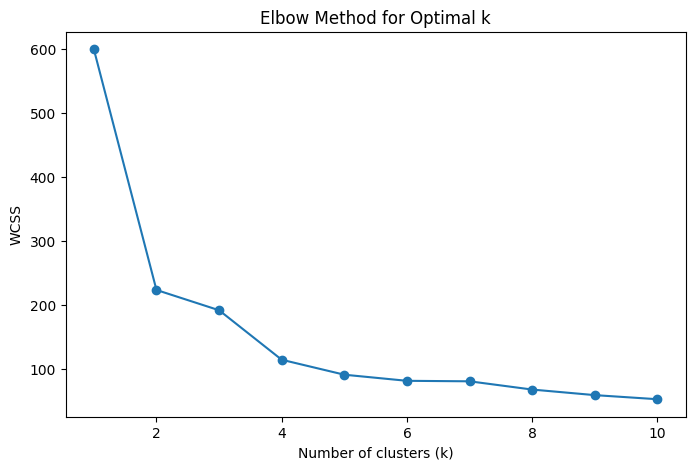

In [8]:
X_scaled = scaler.fit_transform(X)

# Determine optimal number of clusters using Elbow Method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS')

plt.show()

In [9]:
# Fit K-Means with k=3 (based on elbow method)
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    random_state=42
)

y_kmeans = kmeans.fit_predict(X_scaled)

# Add cluster labels to DataFrame
df['Cluster'] = y_kmeans

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Cluster
0,1,5.1,3.5,1.4,0.2,Iris-setosa,1
1,2,4.9,3.0,1.4,0.2,Iris-setosa,2
2,3,4.7,3.2,1.3,0.2,Iris-setosa,2
3,4,4.6,3.1,1.5,0.2,Iris-setosa,2
4,5,5.0,3.6,1.4,0.2,Iris-setosa,1


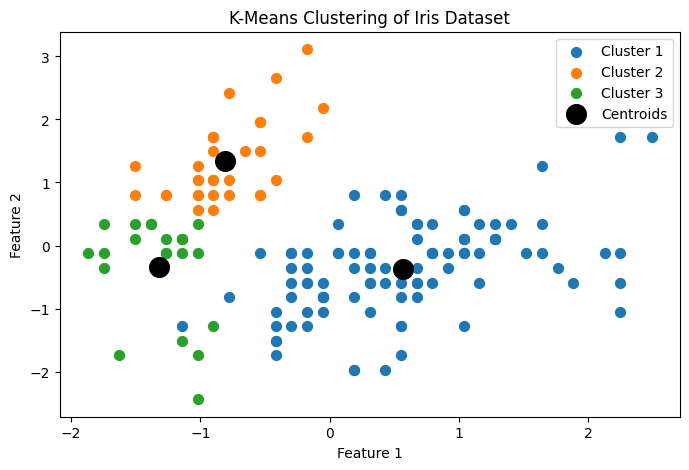

In [10]:
# Optional: Visualize clusters (2D scatter using first two features)
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[y_kmeans == 0, 0],
    X_scaled[y_kmeans == 0, 1],
    s=50,
    label='Cluster 1'
)

plt.scatter(
    X_scaled[y_kmeans == 1, 0],
    X_scaled[y_kmeans == 1, 1],
    s=50,
    label='Cluster 2'
)

plt.scatter(
    X_scaled[y_kmeans == 2, 0],
    X_scaled[y_kmeans == 2, 1],
    s=50,
    label='Cluster 3'
)

# Plot centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    c='black',
    label='Centroids'
)

plt.title('K-Means Clustering of Iris Dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()

plt.show()